# 01 - Exploratory data analysis (D1)

**Purpose:** inform the knowledge-graph design. This is *not* an attrition-prediction exercise.

By the end this notebook must answer:

1. What uniquely identifies an employee, and is it clean?
2. Which columns are constant / carry no information?
3. Which columns are categorical (candidate nodes) vs numeric/ordinal (properties)?
4. Which numeric columns are coded scales, what do the codes mean, and are all codes used?
5. How do Department, JobRole and JobLevel relate (is a REPORTS_TO hierarchy believable)?
6. What is attrition overall and by Department, JobRole, OverTime, JobLevel?
7. Which policy thresholds select a sensible number of employees?

## 0. Setup and load

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

DATA_PATH = Path("..") / "data" / "raw" / "WA_Fn-UseC_-HR-Employee-Attrition.csv"
DATA_PATH.resolve()

PosixPath('/Users/Shivanshu/Documents/hr-project/hr-knowledge-graph/data/raw/WA_Fn-UseC_-HR-Employee-Attrition.csv')

**Check the raw bytes before trusting `read_csv`.** A UTF-8 BOM (`EF BB BF`) at the start of the file silently turns the first column name into `\ufeffAge`.

In [2]:
with open(DATA_PATH, "rb") as f:
    print(f.read(10))

b'\xef\xbb\xbfAge,Att'


In [3]:
df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")
print(df.shape)
print(df.columns[0].encode())  # should be b'Age', not b'\xef\xbb\xbfAge'

(1470, 35)
b'Age'


In [4]:
df.dtypes.value_counts()

int64    26
str       9
Name: count, dtype: int64

In [5]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


## 1. Q1: What uniquely identifies an employee, and is it clean?

A graph node needs a stable key. We test the candidate key (`EmployeeNumber`) rather than assume it, and check the table for nulls, duplicate rows and stray whitespace that would create phantom nodes.

In [6]:
# TODO(me): which column(s) do you think are the candidate key? Write your guess before running the checks below.
key = "EmployeeNumber"

print("rows:            ", len(df))
print("unique key:      ", df[key].nunique())
print("key is unique:   ", df[key].is_unique)
print("null keys:       ", df[key].isna().sum())
print("min / max:       ", df[key].min(), "/", df[key].max())

rows:             1470
unique key:       1470
key is unique:    True
null keys:        0
min / max:        1 / 2068


In [7]:
# Are the IDs contiguous? Gaps are fine for a key, but they tell us the ID is not a row index.
full_range = set(range(df[key].min(), df[key].max() + 1))
missing_ids = sorted(full_range - set(df[key]))
print("gaps in ID range:", len(missing_ids), "e.g.", missing_ids[:10])

gaps in ID range: 598 e.g. [3, 6, 9, 17, 25, 29, 34, 37, 43, 44]


In [8]:
# Nulls anywhere?
nulls = df.isna().sum()
print("total nulls:", nulls.sum())
nulls[nulls > 0]

total nulls: 0


Series([], dtype: int64)

In [9]:
# Duplicates: whole-row, and rows identical once the ID is ignored.
print("fully duplicated rows:      ", df.duplicated().sum())
print("duplicates ignoring the ID: ", df.drop(columns=[key]).duplicated().sum())

fully duplicated rows:       0
duplicates ignoring the ID:  0


In [10]:
# Text hygiene: leading/trailing whitespace or case variants would split one category into two nodes.
text_cols = df.select_dtypes(include="object").columns
for col in text_cols:
    stripped = df[col].str.strip()
    ws = (df[col] != stripped).sum()
    case_variants = stripped.nunique() - stripped.str.lower().nunique()
    print(f"{col:16s} whitespace issues: {ws}   case variants: {case_variants}")

Attrition        whitespace issues: 0   case variants: 0
BusinessTravel   whitespace issues: 0   case variants: 0
Department       whitespace issues: 0   case variants: 0
EducationField   whitespace issues: 0   case variants: 0
Gender           whitespace issues: 0   case variants: 0
JobRole          whitespace issues: 0   case variants: 0
MaritalStatus    whitespace issues: 0   case variants: 0
Over18           whitespace issues: 0   case variants: 0
OverTime         whitespace issues: 0   case variants: 0


/var/folders/xp/trm7t7vn3px018dsyb6xd7b40000gp/T/ipykernel_86931/726485933.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_cols = df.select_dtypes(include="object").columns


### My answer

*(Write your answer here: what is the key, is it clean, anything that surprised you?)*

## 2. Q2: Which columns are constant or carry no information?

A column that has one value for every employee cannot distinguish anyone, so as a node or property it adds storage and noise and nothing else. We look for three kinds: exact constants, near-constants, and columns that are copies of each other.

In [11]:
# Distinct values per column, fewest first.
nunique = df.nunique().sort_values()
nunique.head(12)

Over18                     1
StandardHours              1
EmployeeCount              1
Gender                     2
Attrition                  2
PerformanceRating          2
OverTime                   2
MaritalStatus              3
Department                 3
BusinessTravel             3
StockOptionLevel           4
EnvironmentSatisfaction    4
dtype: int64

In [12]:
# Exact constants: one distinct value.
constant_cols = nunique[nunique == 1].index.tolist()
for col in constant_cols:
    print(f"{col:16s} always = {df[col].iloc[0]!r}")

Over18           always = 'Y'
StandardHours    always = np.int64(80)
EmployeeCount    always = np.int64(1)


In [13]:
# Near-constants: share of the most common value.
# TODO(me): what share would make you drop a column? 0.95? 0.99? Decide and justify before reading the table.
top_share = df.apply(lambda s: s.value_counts(normalize=True).iloc[0]).sort_values(ascending=False)
top_share.head(8)

Over18               1.000000
StandardHours        1.000000
EmployeeCount        1.000000
PerformanceRating    0.846259
Attrition            0.838776
OverTime             0.717007
BusinessTravel       0.709524
Department           0.653741
dtype: float64

In [14]:
# Exact copies: any two columns holding identical values on every row?
dup_cols = df.T.duplicated(keep=False)
print("columns that are copies of another:", df.columns[dup_cols].tolist())

columns that are copies of another: []


In [15]:
# Suspicious pay columns: three "rate" columns beside MonthlyIncome. Do they relate to income at all?
pay = ["MonthlyIncome", "MonthlyRate", "DailyRate", "HourlyRate"]
df[pay].corr().round(2)

,MonthlyIncome,MonthlyRate,DailyRate,HourlyRate
MonthlyIncome,1.00,0.03,0.01,-0.02
MonthlyRate,0.03,1.00,-0.03,-0.02
DailyRate,0.01,-0.03,1.00,0.02
HourlyRate,-0.02,-0.02,0.02,1.00


In [16]:
# Mechanical relationships: is MonthlyIncome a function of JobLevel? (should be, if pay is meaningful)
df.groupby("JobLevel")[["MonthlyIncome", "MonthlyRate", "DailyRate", "HourlyRate"]].mean().round(0)

,MonthlyIncome,MonthlyRate,DailyRate,HourlyRate
JobLevel,,,,
1,2787.0,13686.0,804.0,67.0
2,5502.0,14775.0,794.0,66.0
3,9817.0,14634.0,830.0,64.0
4,15504.0,14539.0,774.0,66.0
5,19192.0,14312.0,815.0,66.0


### My answer

*(Which columns would you drop and why? Which are borderline and what is your rule?)*

## 3. Q3: Categorical (candidate nodes) vs numeric/ordinal (properties)

Rule of thumb for property graphs: a value becomes a **node** when many employees *share* it and you want to traverse through it (Department, JobRole). It stays a **property** when it describes one employee (Age, MonthlyIncome). Cardinality and the value set give the evidence; the decision is yours.

We first remove what Q1 and Q2 ruled out.

In [17]:
drop_cols = ["Over18", "StandardHours", "EmployeeCount", "MonthlyRate", "DailyRate", "HourlyRate"]
key = "EmployeeNumber"

work = df.drop(columns=drop_cols)
feature_cols = [c for c in work.columns if c != key]
print(len(df.columns), "->", len(work.columns), "columns (", len(feature_cols), "features + key )")

35 -> 29 columns ( 28 features + key )


In [18]:
# Text columns: cardinality and full value set.
for col in work.select_dtypes(include="object").columns:
    vals = sorted(work[col].unique())
    print(f"{col} ({len(vals)}): {vals}\n")

Attrition (2): ['No', 'Yes']

BusinessTravel (3): ['Non-Travel', 'Travel_Frequently', 'Travel_Rarely']

Department (3): ['Human Resources', 'Research & Development', 'Sales']

EducationField (6): ['Human Resources', 'Life Sciences', 'Marketing', 'Medical', 'Other', 'Technical Degree']

Gender (2): ['Female', 'Male']

JobRole (9): ['Healthcare Representative', 'Human Resources', 'Laboratory Technician', 'Manager', 'Manufacturing Director', 'Research Director', 'Research Scientist', 'Sales Executive', 'Sales Representative']

MaritalStatus (3): ['Divorced', 'Married', 'Single']

OverTime (2): ['No', 'Yes']



/var/folders/xp/trm7t7vn3px018dsyb6xd7b40000gp/T/ipykernel_86931/235608564.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in work.select_dtypes(include="object").columns:


In [19]:
# Integer columns: cardinality, range, and (when small) the value set.
rows = []
for col in work.select_dtypes(include="number").columns.drop(key):
    s = work[col]
    n = s.nunique()
    rows.append({
        "column": col,
        "nunique": n,
        "min": s.min(),
        "max": s.max(),
        "values": sorted(s.unique().tolist()) if n <= 10 else "-",
    })
pd.DataFrame(rows).sort_values("nunique").reset_index(drop=True)

,column,nunique,min,max,values
0,PerformanceRating,2,3,4,"[3, 4]"
1,WorkLifeBalance,4,1,4,"[1, 2, 3, 4]"
2,EnvironmentSatisfaction,4,1,4,"[1, 2, 3, 4]"
3,JobInvolvement,4,1,4,"[1, 2, 3, 4]"
4,JobSatisfaction,4,1,4,"[1, 2, 3, 4]"
5,RelationshipSatisfaction,4,1,4,"[1, 2, 3, 4]"
6,StockOptionLevel,4,0,3,"[0, 1, 2, 3]"
7,Education,5,1,5,"[1, 2, 3, 4, 5]"
8,JobLevel,5,1,5,"[1, 2, 3, 4, 5]"
9,TrainingTimesLastYear,7,0,6,"[0, 1, 2, 3, 4, 5, 6]"


In [20]:
# TODO(me): fill in your classification below, then run it. Use only column names that exist in `feature_cols`.
# node_candidates : values shared by many employees that you would traverse through
# properties     : values describing one employee
node_candidates = []   # TODO(me)
properties = []        # TODO(me)

unassigned = sorted(set(feature_cols) - set(node_candidates) - set(properties))
print("unassigned:", unassigned)

unassigned: ['Age', 'Attrition', 'BusinessTravel', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EnvironmentSatisfaction', 'Gender', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'NumCompaniesWorked', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


### My answer

*(Which columns become nodes and which become properties? Where was it a hard call, and why?)*

## 4. Q4: Which numeric columns are really coded scales?

A coded scale is an integer standing in for a label (1 = Low ... 4 = Very High). Averaging or comparing the raw numbers is only valid if the codes are ordered and roughly evenly spaced, so we need the meaning of each code and to know which codes actually occur.

In [21]:
scale_cols = [
    "Education", "EnvironmentSatisfaction", "JobInvolvement", "JobSatisfaction",
    "RelationshipSatisfaction", "WorkLifeBalance", "PerformanceRating",
    "StockOptionLevel", "JobLevel",
]

# Employees per code, one row per column. NaN means the code never occurs.
counts = pd.DataFrame({c: df[c].value_counts().sort_index() for c in scale_cols}).T
counts

,0,1,2,3,4,5
Education,NaN,170.0,282.0,572.0,398.0,48.0
EnvironmentSatisfaction,NaN,284.0,287.0,453.0,446.0,NaN
JobInvolvement,NaN,83.0,375.0,868.0,144.0,NaN
JobSatisfaction,NaN,289.0,280.0,442.0,459.0,NaN
RelationshipSatisfaction,NaN,276.0,303.0,459.0,432.0,NaN
WorkLifeBalance,NaN,80.0,344.0,893.0,153.0,NaN
PerformanceRating,NaN,NaN,NaN,1244.0,226.0,NaN
StockOptionLevel,631.0,596.0,158.0,85.0,NaN,NaN
JobLevel,NaN,543.0,534.0,218.0,106.0,69.0


In [22]:
# Documented meanings. These are copied from the Kaggle dataset description from memory,
# so check each against the dataset page before relying on them.
# TODO(me): JobLevel and StockOptionLevel have no official labels. What do you think each code means, and how would you find out?
code_meaning = {
    "Education": {1: "Below College", 2: "College", 3: "Bachelor", 4: "Master", 5: "Doctor"},
    "EnvironmentSatisfaction": {1: "Low", 2: "Medium", 3: "High", 4: "Very High"},
    "JobInvolvement": {1: "Low", 2: "Medium", 3: "High", 4: "Very High"},
    "JobSatisfaction": {1: "Low", 2: "Medium", 3: "High", 4: "Very High"},
    "RelationshipSatisfaction": {1: "Low", 2: "Medium", 3: "High", 4: "Very High"},
    "WorkLifeBalance": {1: "Bad", 2: "Good", 3: "Better", 4: "Best"},
    "PerformanceRating": {1: "Low", 2: "Good", 3: "Excellent", 4: "Outstanding"},
}

# Documented codes vs codes found in the data.
for col, labels in code_meaning.items():
    observed = set(df[col].unique())
    unused = sorted(set(labels) - observed)
    undocumented = sorted(observed - set(labels))
    print(f"{col:26s} unused codes: {unused}   undocumented codes: {undocumented}")

Education                  unused codes: []   undocumented codes: []
EnvironmentSatisfaction    unused codes: []   undocumented codes: []
JobInvolvement             unused codes: []   undocumented codes: []
JobSatisfaction            unused codes: []   undocumented codes: []
RelationshipSatisfaction   unused codes: []   undocumented codes: []
WorkLifeBalance            unused codes: []   undocumented codes: []
PerformanceRating          unused codes: [1, 2]   undocumented codes: []


In [23]:
# Share of employees per code, so imbalance is visible.
(counts.div(counts.sum(axis=1), axis=0) * 100).round(1)

,0,1,2,3,4,5
Education,NaN,11.6,19.2,38.9,27.1,3.3
EnvironmentSatisfaction,NaN,19.3,19.5,30.8,30.3,NaN
JobInvolvement,NaN,5.6,25.5,59.0,9.8,NaN
JobSatisfaction,NaN,19.7,19.0,30.1,31.2,NaN
RelationshipSatisfaction,NaN,18.8,20.6,31.2,29.4,NaN
WorkLifeBalance,NaN,5.4,23.4,60.7,10.4,NaN
PerformanceRating,NaN,NaN,NaN,84.6,15.4,NaN
StockOptionLevel,42.9,40.5,10.7,5.8,NaN,NaN
JobLevel,NaN,36.9,36.3,14.8,7.2,4.7


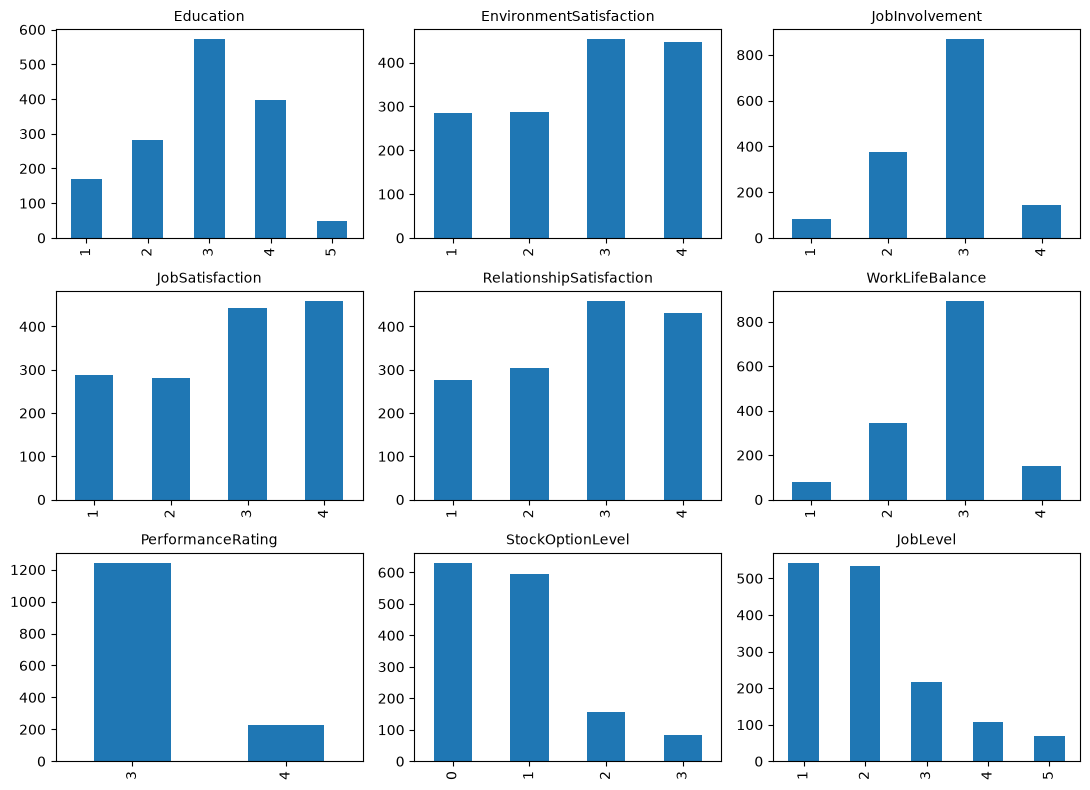

In [24]:
fig, axes = plt.subplots(3, 3, figsize=(11, 8))
for ax, col in zip(axes.ravel(), scale_cols):
    df[col].value_counts().sort_index().plot.bar(ax=ax)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")
plt.tight_layout()

### My answer

*(Which columns are coded scales? Are any codes unused? Are they ordinal, and is it safe to average them? What does this change in your Q3 hard calls?)*

## 5. Q5: How do Department, JobRole and JobLevel relate?

The CSV has no manager column, so on D3 we must *generate* a REPORTS_TO hierarchy. That only looks believable if (a) each role sits in one department and (b) each department has people at several levels, so every employee has someone senior to report to.

In [25]:
# Employees per Department x JobRole.
pd.crosstab(df["JobRole"], df["Department"], margins=True)

Department,Human Resources,Research & Development,Sales,All
JobRole,,,,
Healthcare Representative,0,131,0,131
Human Resources,52,0,0,52
Laboratory Technician,0,259,0,259
Manager,11,54,37,102
Manufacturing Director,0,145,0,145
Research Director,0,80,0,80
Research Scientist,0,292,0,292
Sales Executive,0,0,326,326
Sales Representative,0,0,83,83


In [26]:
# Does each JobRole belong to exactly one Department?
depts_per_role = df.groupby("JobRole")["Department"].nunique()
print(depts_per_role.sort_values(ascending=False).to_string())
print("\nroles in more than one department:", (depts_per_role > 1).sum())

JobRole
Manager                      3
Healthcare Representative    1
Human Resources              1
Laboratory Technician        1
Manufacturing Director       1
Research Director            1
Research Scientist           1
Sales Executive              1
Sales Representative         1

roles in more than one department: 1


In [27]:
# Employees per Department x JobLevel.
dept_level = pd.crosstab(df["Department"], df["JobLevel"], margins=True)
dept_level

JobLevel,1,2,3,4,5,All
Department,,,,,,
Human Resources,33,13,6,4,7,63
Research & Development,434,281,129,68,49,961
Sales,76,240,83,34,13,446
All,543,534,218,106,69,1470


In [28]:
# Employees per JobRole x JobLevel: is a role tied to particular levels?
pd.crosstab(df["JobRole"], df["JobLevel"], margins=True)

JobLevel,1,2,3,4,5,All
JobRole,,,,,,
Healthcare Representative,0,78,44,9,0,131
Human Resources,33,13,6,0,0,52
Laboratory Technician,200,56,3,0,0,259
Manager,0,0,12,47,43,102
Manufacturing Director,0,90,45,10,0,145
Research Director,0,0,28,26,26,80
Research Scientist,234,57,1,0,0,292
Sales Executive,0,233,79,14,0,326
Sales Representative,76,7,0,0,0,83


In [29]:
# REPORTS_TO feasibility. For each Department and level, how many people sit exactly one level above?
# TODO(me): decide your rule before reading this. Must a manager be in the same department? Exactly one level up, or any higher level?
levels = sorted(df["JobLevel"].unique())
rows = []
for dept, g in df.groupby("Department"):
    counts = g["JobLevel"].value_counts()
    for lvl in levels[:-1]:
        n = counts.get(lvl, 0)
        above = counts.get(lvl + 1, 0)
        any_above = counts[counts.index > lvl].sum()
        rows.append({
            "Department": dept, "level": lvl, "employees": n,
            "one_level_up": above, "any_higher": any_above,
            "per_manager": round(n / above, 1) if above else None,
        })
reports = pd.DataFrame(rows)
reports

,Department,level,employees,one_level_up,any_higher,per_manager
0,Human Resources,1,33,13,30,2.5
1,Human Resources,2,13,6,17,2.2
2,Human Resources,3,6,4,11,1.5
3,Human Resources,4,4,7,7,0.6
4,Research & Development,1,434,281,527,1.5
5,Research & Development,2,281,129,246,2.2
6,Research & Development,3,129,68,117,1.9
7,Research & Development,4,68,49,49,1.4
8,Sales,1,76,240,370,0.3
9,Sales,2,240,83,130,2.9


In [30]:
# Span of control if only manager-type roles may manage.
# TODO(me): which roles count as managers? These two are prefilled because they only occur at levels 3-5. Edit if you disagree.
manager_roles = ["Manager", "Research Director"]

by_dept = df.groupby("Department").agg(employees=("EmployeeNumber", "size"))
by_dept["managers"] = df[df["JobRole"].isin(manager_roles)].groupby("Department").size()
by_dept["non_managers"] = by_dept["employees"] - by_dept["managers"]
by_dept["per_manager"] = (by_dept["non_managers"] / by_dept["managers"]).round(1)
by_dept

,employees,managers,non_managers,per_manager
Department,,,,
Human Resources,63,11,52,4.7
Research & Development,961,134,827,6.2
Sales,446,37,409,11.1


In [31]:
# Tenure rule: a manager must have been at the company at least as long as the employee has had their current manager.
# For each employee below the top level, count same-department, higher-level people who satisfy that.
top = df["JobLevel"].max()
emp = df[df["JobLevel"] < top]

def n_candidates(row):
    pool = df[
        (df["Department"] == row["Department"])
        & (df["JobLevel"] > row["JobLevel"])
        & (df["YearsAtCompany"] >= row["YearsWithCurrManager"])
    ]
    return len(pool)

cand = emp.apply(n_candidates, axis=1)
print("non-top employees:     ", len(emp))
print("with zero candidates:  ", (cand == 0).sum())
emp.loc[cand == 0, ["EmployeeNumber", "Department", "JobLevel", "YearsAtCompany", "YearsWithCurrManager"]].head(10)

non-top employees:      1401
with zero candidates:   0


,EmployeeNumber,Department,JobLevel,YearsAtCompany,YearsWithCurrManager


### My answer

*(Is JobRole -> Department one-to-one-per-role? Does every Department have people at every level? Where would a REPORTS_TO hierarchy break, and what rule will you use on D3?)*

## 6. Q6: Attrition overall and by Department, JobRole, OverTime, JobLevel

These tables are the **ground truth** for D5: when you rewrite them as Cypher queries, the numbers must match exactly. We always show the group size next to the rate, because a rate on 11 people means much less than a rate on 900.

In [32]:
leaver = (df["Attrition"] == "Yes")
print("employees:", len(df))
print("leavers:  ", leaver.sum())
print(f"attrition rate: {leaver.mean():.1%}")

employees: 1470
leavers:   237
attrition rate: 16.1%


In [33]:
overall = leaver.mean() * 100

def attrition_by(col):
    g = df.groupby(col)["Attrition"].agg(
        employees="size",
        leavers=lambda s: (s == "Yes").sum(),
    )
    g["rate_pct"] = (g["leavers"] / g["employees"] * 100).round(1)
    g["vs_overall_pp"] = (g["rate_pct"] - overall).round(1)
    return g

for col in ["Department", "JobRole", "OverTime", "JobLevel"]:
    print(f"--- {col} ---")
    print(attrition_by(col).sort_values("rate_pct", ascending=False).to_string(), "\n")

--- Department ---
                        employees  leavers  rate_pct  vs_overall_pp
Department                                                         
Sales                         446       92      20.6            4.5
Human Resources                63       12      19.0            2.9
Research & Development        961      133      13.8           -2.3 

--- JobRole ---
                           employees  leavers  rate_pct  vs_overall_pp
JobRole                                                               
Sales Representative              83       33      39.8           23.7
Laboratory Technician            259       62      23.9            7.8
Human Resources                   52       12      23.1            7.0
Sales Executive                  326       57      17.5            1.4
Research Scientist               292       47      16.1           -0.0
Healthcare Representative        131        9       6.9           -9.2
Manufacturing Director           145       10       6.9

In [34]:
# Rough 95% margin of error for a group's rate, around the overall rate p.
# Rule of thumb only: ~25 groups are compared, so a couple will pass by chance.
# TODO(me): choose your rule. Minimum group size, and how the difference must compare to the margin.
MIN_N = 30   # TODO(me)

p = leaver.mean()

def with_margin(col):
    g = attrition_by(col)
    g["margin_pp"] = (1.96 * (p * (1 - p) / g["employees"]) ** 0.5 * 100).round(1)
    g["trusted"] = (g["employees"] >= MIN_N) & (g["vs_overall_pp"].abs() > g["margin_pp"])
    return g

for col in ["Department", "JobRole", "OverTime", "JobLevel"]:
    print(f"--- {col} ---")
    print(with_margin(col)[["employees", "rate_pct", "vs_overall_pp", "margin_pp", "trusted"]].to_string(), "\n")

--- Department ---
                        employees  rate_pct  vs_overall_pp  margin_pp  trusted
Department                                                                    
Human Resources                63      19.0            2.9        9.1    False
Research & Development        961      13.8           -2.3        2.3    False
Sales                         446      20.6            4.5        3.4     True 

--- JobRole ---
                           employees  rate_pct  vs_overall_pp  margin_pp  trusted
JobRole                                                                          
Healthcare Representative        131       6.9           -9.2        6.3     True
Human Resources                   52      23.1            7.0       10.0    False
Laboratory Technician            259      23.9            7.8        4.5     True
Manager                          102       4.9          -11.2        7.1     True
Manufacturing Director           145       6.9           -9.2        6.0    

In [35]:
# JobRole is department-scoped in the graph (Q5, option B). How big are those groups?
by_dept_role = df.groupby(["Department", "JobRole"])["Attrition"].agg(
    employees="size", leavers=lambda s: (s == "Yes").sum()
)
by_dept_role["rate_pct"] = (by_dept_role["leavers"] / by_dept_role["employees"] * 100).round(1)
by_dept_role.sort_values("employees")

employees  leavers  rate_pct
Department             JobRole                                                
Human Resources        Manager                           11        0       0.0
Sales                  Manager                           37        2       5.4
Human Resources        Human Resources                   52       12      23.1
Research & Development Manager                           54        3       5.6
                       Research Director                 80        2       2.5
Sales                  Sales Representative              83       33      39.8
Research & Development Healthcare Representative        131        9       6.9
                       Manufacturing Director           145       10       6.9
                       Laboratory Technician            259       62      23.9
                       Research Scientist               292       47      16.1
Sales                  Sales Executive                  326       57      17.5

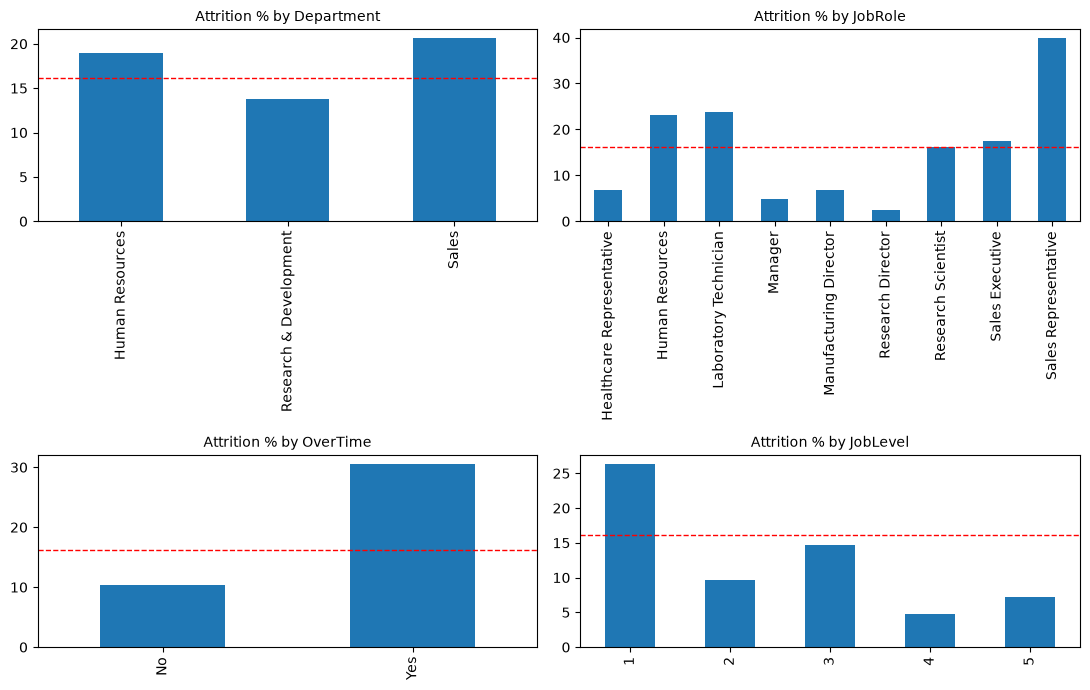

In [36]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), ["Department", "JobRole", "OverTime", "JobLevel"]):
    attrition_by(col)["rate_pct"].plot.bar(ax=ax)
    ax.axhline(overall, color="red", linestyle="--", linewidth=1)
    ax.set_title(f"Attrition % by {col}", fontsize=10)
    ax.set_xlabel("")
plt.tight_layout()

### My answer

*(Which differences do you trust and which do you not, given group size? Which of these tables would you turn into a Cypher query first, and what must the graph contain for it to work?)*

## 7. Q7: Which thresholds make a sensible policy rule?

On D8 you will write rules such as *promotion eligibility* using `JobLevel`, `YearsInCurrentRole` and `PerformanceRating`. A rule that selects nobody, or nearly everybody, is useless for demonstrating graph-grounded answers. We sweep thresholds and look at how many employees each selects.

In [37]:
# The inputs: how are they distributed?
print(df["YearsInCurrentRole"].describe().round(1).to_string())
print()
print("YearsInCurrentRole counts:")
print(df["YearsInCurrentRole"].value_counts().sort_index().to_string())

count    1470.0
mean        4.2
std         3.6
min         0.0
25%         2.0
50%         3.0
75%         7.0
max        18.0

YearsInCurrentRole counts:
YearsInCurrentRole
0     244
1      57
2     372
3     135
4     104
5      36
6      37
7     222
8      89
9      67
10     29
11     22
12     10
13     14
14     11
15      8
16      7
17      4
18      2


In [38]:
# Sweep: % of the workforce selected by "YearsInCurrentRole >= y AND PerformanceRating >= r AND JobLevel < max_level".
# TODO(me): can anyone at JobLevel 5 be promoted? Set max_level accordingly (promotable means JobLevel < max_level).
max_level = 5   # TODO(me)

base = df["JobLevel"] < max_level
years = range(0, 11)
ratings = [3, 4]

counts = pd.DataFrame(
    {f"rating>={r}": [int((base & (df["YearsInCurrentRole"] >= y) & (df["PerformanceRating"] >= r)).sum()) for y in years]
     for r in ratings},
    index=pd.Index(list(years), name="years_in_role>="),
)
pct = (counts / len(df) * 100).round(1)
print("employees selected:"); print(counts.to_string()); print()
print("% of workforce:");    print(pct.to_string())

employees selected:
                 rating>=3  rating>=4
years_in_role>=                      
0                     1401        219
1                     1167        182
2                     1112        175
3                      751        130
4                      619        109
5                      519         90
6                      484         80
7                      450         76
8                      236         44
9                      152         30
10                      91         19

% of workforce:
                 rating>=3  rating>=4
years_in_role>=                      
0                     95.3       14.9
1                     79.4       12.4
2                     75.6       11.9
3                     51.1        8.8
4                     42.1        7.4
5                     35.3        6.1
6                     32.9        5.4
7                     30.6        5.2
8                     16.1        3.0
9                     10.3        2.0
10           

In [39]:
# Add a second knob. YearsSinceLastPromotion: should "stuck" employees qualify?
# Same sweep for rating>=4 only, split by YearsSinceLastPromotion.
for ysp in [0, 1, 2, 3, 5]:
    row = []
    for y in range(0, 8):
        sel = base & (df["PerformanceRating"] >= 4) & (df["YearsInCurrentRole"] >= y) & (df["YearsSinceLastPromotion"] >= ysp)
        row.append(int(sel.sum()))
    print(f"since_promo>={ysp}:", row)
print("columns above: years_in_role >= 0..7")

since_promo>=0: [219, 182, 175, 130, 109, 90, 80, 76]
since_promo>=1: [125, 119, 118, 94, 83, 76, 67, 65]
since_promo>=2: [78, 75, 75, 61, 56, 55, 53, 51]
since_promo>=3: [60, 57, 57, 55, 51, 51, 50, 48]
since_promo>=5: [44, 41, 41, 40, 39, 39, 38, 36]
columns above: years_in_role >= 0..7


In [41]:
# TODO(me): once you have chosen thresholds, set them here (leave None to skip) and check WHO is selected.
MIN_YEARS = 2    # TODO(me)
MIN_RATING = 4   # TODO(me)

if MIN_YEARS is None or MIN_RATING is None:
    print("set MIN_YEARS and MIN_RATING first")
else:
    sel = df[base & (df["YearsInCurrentRole"] >= MIN_YEARS) & (df["PerformanceRating"] >= MIN_RATING)]
    print(f"selected: {len(sel)} ({len(sel) / len(df):.1%})")
    print(sel["Department"].value_counts().to_string())
    print(sel["JobLevel"].value_counts().sort_index().to_string())
    print(f"attrition among selected: {(sel['Attrition'] == 'Yes').mean():.1%}")

selected: 175 (11.9%)
Department
Research & Development    115
Sales                      54
Human Resources             6
JobLevel
1    60
2    70
3    28
4    17
attrition among selected: 13.1%


### My answer

*(What share of the workforce counts as "sensible" for a policy demo, and why? Which thresholds did you pick? Does the selection cover several departments and levels, or is it lopsided?)*

## 8. Graph design implications

Compiled from the decisions made in sections 1-7. Full reasoning and rejected alternatives are logged in `NOTES.md`.

- **Key:** `Employee` keyed by `EmployeeNumber` with a uniqueness constraint. Rejected: row index.
- **Dropped:** `Over18`, `StandardHours`, `EmployeeCount` (constants); `MonthlyRate`, `DailyRate`, `HourlyRate` (uncorrelated with income and flat across levels).
- **Nodes:** only `Employee`, `Department`, `JobRole`. Rejected: nodes for `Attrition`, `OverTime`, `BusinessTravel`, `PerformanceRating`, etc. (supernodes or quantities).
- **Properties:** all other columns. Coded scales stay ordinal integers (median/mode, never mean); `JobLevel` and `StockOptionLevel` are unlabeled in the source. Rejected: invented labels.
- **`attrition` boolean:** explicit mapping at load, fail on unexpected values. Rejected: string.
- **Role modelling:** department-scoped `JobRole` nodes (because `Manager` is in 3 departments), plus an explicit `Employee -> Department` edge. Rejected: one shared `Manager` node.
- **`REPORTS_TO` rule:** same department, JobRole in {Manager, Research Director}, strictly higher level (nearest first), manager `YearsAtCompany` >= employee `YearsWithCurrManager`. Rejected: any higher level; including Manufacturing Director.
- **Roots:** 69 level-5 employees have no `REPORTS_TO`; GraphRAG says "no manager data in source". Rejected: invented CEO node.
- **Reporting rule:** trust a rate only if n >= 30 and the difference exceeds the margin, judged per row. Ground truth: 1470 / 237 / 16.1%.
- **Policy inputs:** promotion eligibility = `YearsInCurrentRole >= 2`, `PerformanceRating >= 4`, `JobLevel < 5` (175 employees, 11.9%). The level-5 exclusion lives only in the rule.